In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

# --- 1. DATA PREPARATION ---
# Keras has this dataset built-in.
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# NORMALIZE: Pixel values are 0-255. We scale them to 0-1 for the neural net.
X_train = X_train / 255.0
X_test = X_test / 255.0

print(f"Data Loaded. X_train shape: {X_train.shape}")
# Shape is (60000, 28, 28). That means 60,000 images, each 28 pixels tall, 28 wide.

# --- 2. BUILD MODEL ---
model = Sequential([
    Input(shape=(28, 28)),     # The input is a 2D image
    Flatten(),                 # CRITICAL STEP: Unstack the 2D grid into a long 1D line (28*28 = 784 pixels)
    Dense(128, activation='relu'), # Hidden layer
    Dense(10, activation='softmax') # Output: 10 neurons (one for each digit 0-9)
])

# We use 'sparse_categorical_crossentropy' because the answer is a category (0-9), not a binary yes/no.
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# --- 3. TRAIN ---
print("\nStarting Training on Images...")
model.fit(X_train, y_train, epochs=5)

# --- 4. PREDICT ---
# Pick a random image in the test set
random_index = np.random.randint(0, len(X_test))
test_image = X_test[random_index]
actual_label = y_test[random_index]

# Add a batch dimension (The model expects a list of images, not just one)
prediction = model.predict(np.expand_dims(test_image, axis=0))
predicted_label = np.argmax(prediction) # Which neuron had the highest value?

print(f"\nActual Number written: {actual_label}")
print(f"Model Predicted: {predicted_label}")

Data Loaded. X_train shape: (60000, 28, 28)

Starting Training on Images...
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8728 - loss: 0.4410
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9628 - loss: 0.1239
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9753 - loss: 0.0813
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9819 - loss: 0.0585
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9869 - loss: 0.0438
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step

Actual Number written: 3
Model Predicted: 3


In [2]:
# --- 5. EVALUATE ---
print("\nEvaluating model performance on the test set...")
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")


Evaluating model performance on the test set...
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9739 - loss: 0.0871
Test Loss: 0.0747
Test Accuracy: 0.9780


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step


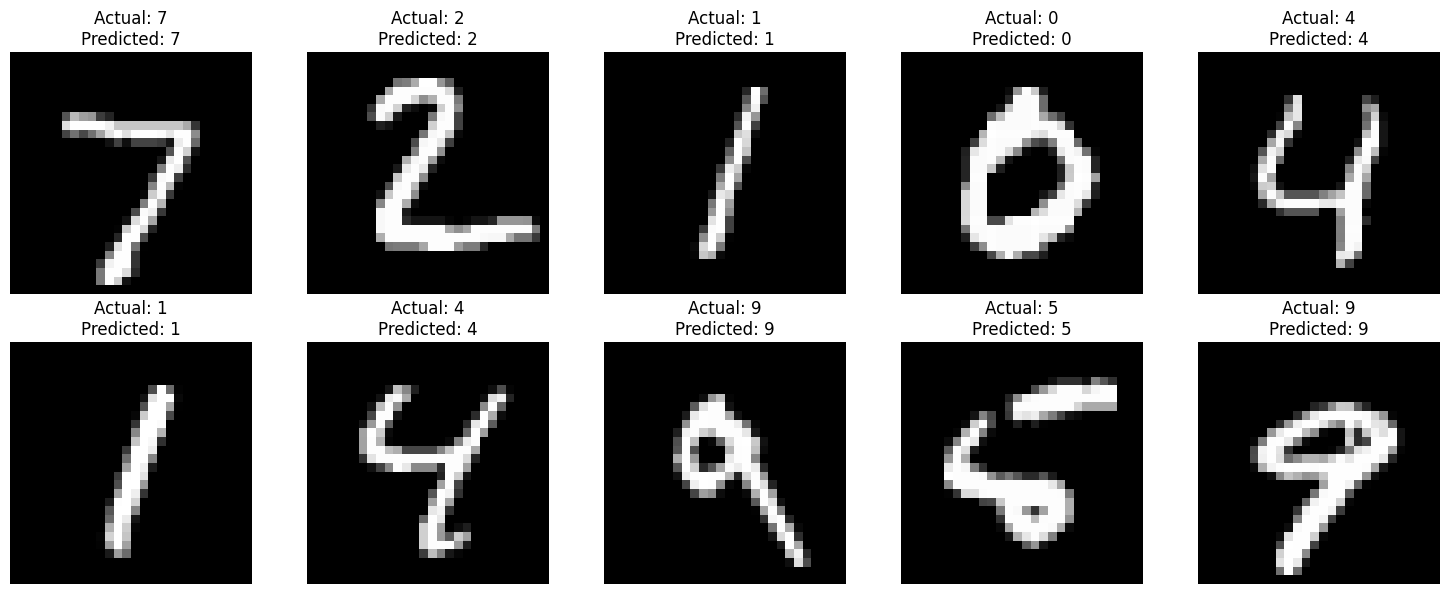

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Get the first 10 images from the test set
num_images_to_show = 10
sample_images = X_test[:num_images_to_show]
actual_labels = y_test[:num_images_to_show]

# Make predictions for these images
predictions = model.predict(sample_images)
predicted_labels = np.argmax(predictions, axis=1)

# Plot the images with actual and predicted labels
plt.figure(figsize=(15, 6))
for i in range(num_images_to_show):
    plt.subplot(2, 5, i + 1) # 2 rows, 5 columns
    plt.imshow(sample_images[i], cmap='gray')
    plt.title(f"Actual: {actual_labels[i]}\nPredicted: {predicted_labels[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()